<a href="https://colab.research.google.com/github/PeterMarkus02/PeterMarkus02-DataScience-GenAI-Submissions/blob/main/Copy_of_5_02_Modelling_Hackathon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=1xqQczl0FG-qtNA2_WQYuWePW9oU8irqJ)

# 5.02 Modelling Hackathon
We'll get a chance in this seminar to practice for the in-class test, and also to put what we have learned into practice.

To speed things up, I have done the data/feature engineering for you, you will just need to build it into a data science model. As before, you can use the code from [GitHub](https://github.com/MJMortensonWarwick/IB2AD0_Data_Science_GenerativeAI), from the internet, and/or use the Gemini AI tools.

This is an artificial dataset, and we will be predicting if students achieve a passing grade, which we will call anything above a "D".

We'll start by importing the data:

In [1]:
from google.colab import files
upload = files.upload()

Saving students_two.csv to students_two.csv


Now we will get the data into Pandas and inspect it:

In [2]:
import pandas as pd
df = pd.read_csv("students_two.csv")

df.head()

,Id,Student_Age,High_School_Type,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade
0,5001,21,Other,50%,Yes,No,Private,0,Always,Yes,Yes,No,No,AA
1,5002,20,Other,50%,Yes,No,Private,0,Always,Yes,No,Yes,Yes,AA
2,5003,21,State,50%,No,No,Private,2,Never,No,No,No,Yes,AA
3,5004,18,Private,50%,Yes,No,Bus,2,Always,No,Yes,No,No,AA
4,5005,22,Private,50%,No,No,Bus,12,Always,Yes,No,Yes,Yes,AA


Let's check for missing values:

In [3]:
df.isnull().sum()

,0
Id,0
Student_Age,0
High_School_Type,0
Scholarship,1
Additional_Work,0
Sports_activity,0
Transportation,0
Weekly_Study_Hours,0
Attendance,0
Reading,0


Only one missing value. Let's just drop it out of laziness:

In [4]:
df.dropna(inplace=True)
df.isnull().sum()

,0
Id,0
Student_Age,0
High_School_Type,0
Scholarship,0
Additional_Work,0
Sports_activity,0
Transportation,0
Weekly_Study_Hours,0
Attendance,0
Reading,0


We have an ID column we know won't be predictive ... so let's drop it:

In [5]:
df = df.drop(["Id"], axis=1)
df.head()

,Student_Age,High_School_Type,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade
0,21,Other,50%,Yes,No,Private,0,Always,Yes,Yes,No,No,AA
1,20,Other,50%,Yes,No,Private,0,Always,Yes,No,Yes,Yes,AA
2,21,State,50%,No,No,Private,2,Never,No,No,No,Yes,AA
3,18,Private,50%,Yes,No,Bus,2,Always,No,Yes,No,No,AA
4,22,Private,50%,No,No,Bus,12,Always,Yes,No,Yes,Yes,AA


Next we will convert some of the text features to numbers:

In [6]:
# High school
print(df['High_School_Type'].unique())

['Other' 'State' 'Private']


We can't easily convert these to a number range. Instead we should use one-hot encoding:

In [7]:
df = pd.get_dummies(df, columns=['High_School_Type'], drop_first=True, dtype=int)
df.head()

,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,21,50%,Yes,No,Private,0,Always,Yes,Yes,No,No,AA,0,0
1,20,50%,Yes,No,Private,0,Always,Yes,No,Yes,Yes,AA,0,0
2,21,50%,No,No,Private,2,Never,No,No,No,Yes,AA,0,1
3,18,50%,Yes,No,Bus,2,Always,No,Yes,No,No,AA,1,0
4,22,50%,No,No,Bus,12,Always,Yes,No,Yes,Yes,AA,1,0


We have converted this to two columns (on the far right) - "High_School_Type_Private" and "High_School_Type_State". We do not need the "Other" type as if the student is "Other" then both "Private" and "State" will be 0 (a unique combination). This is controlled by the command _drop\_first=True_. We also specify the data type (_dtype_) as __int__ so we return 0s and 1s rather than True and False.

Next we can look at Scholarship. It needs to be converted from a text representation of a percentage to a number:

In [8]:
df['Scholarship'] = df['Scholarship'].str.replace('%', '').astype(float) / 100
df.head()

,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,21,0.5,Yes,No,Private,0,Always,Yes,Yes,No,No,AA,0,0
1,20,0.5,Yes,No,Private,0,Always,Yes,No,Yes,Yes,AA,0,0
2,21,0.5,No,No,Private,2,Never,No,No,No,Yes,AA,0,1
3,18,0.5,Yes,No,Bus,2,Always,No,Yes,No,No,AA,1,0
4,22,0.5,No,No,Bus,12,Always,Yes,No,Yes,Yes,AA,1,0


"Additional_Work" is next:

In [9]:
# Additional work
print(df['Additional_Work'].unique())

['Yes' 'No']


Two values, so we can convert to 0 and 1:

In [10]:
df['Additional_Work'] = df['Additional_Work'].map({'Yes': 1, 'No': 0})
df.head()

,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,21,0.5,1,No,Private,0,Always,Yes,Yes,No,No,AA,0,0
1,20,0.5,1,No,Private,0,Always,Yes,No,Yes,Yes,AA,0,0
2,21,0.5,0,No,Private,2,Never,No,No,No,Yes,AA,0,1
3,18,0.5,1,No,Bus,2,Always,No,Yes,No,No,AA,1,0
4,22,0.5,0,No,Bus,12,Always,Yes,No,Yes,Yes,AA,1,0


Let's speed up now:

In [11]:
categorical_cols = ['Sports_activity', 'Transportation', 'Attendance', 'Reading', 'Notes', 'Listening_in_Class', 'Project_work', 'Grade']

for col in categorical_cols:
    print(f"Unique values for '{col}': {df[col].unique()}")

Unique values for 'Sports_activity': ['No' 'Yes']
Unique values for 'Transportation': ['Private' 'Bus']
Unique values for 'Attendance': ['Always' 'Never' 'Sometimes' '3']
Unique values for 'Reading': ['Yes' 'No']
Unique values for 'Notes': ['Yes' 'No' '6']
Unique values for 'Listening_in_Class': ['No' 'Yes' '6']
Unique values for 'Project_work': ['No' 'Yes']
Unique values for 'Grade': ['AA' 'BA' 'CC' 'Fail' 'BB' 'CB' 'DD' 'DC']


The values of '6' in 'Notes' and 'Listening_in_Class' make no sense, and neither do '3' for 'Attendance'. We'll be lazy and drop these rows (really we should check with an SME):

In [12]:
df = df[(df['Notes'] != '6') & (df['Listening_in_Class'] != '6') & (df['Attendance'] != '3')]
df.head()

,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,21,0.5,1,No,Private,0,Always,Yes,Yes,No,No,AA,0,0
1,20,0.5,1,No,Private,0,Always,Yes,No,Yes,Yes,AA,0,0
2,21,0.5,0,No,Private,2,Never,No,No,No,Yes,AA,0,1
3,18,0.5,1,No,Bus,2,Always,No,Yes,No,No,AA,1,0
4,22,0.5,0,No,Bus,12,Always,Yes,No,Yes,Yes,AA,1,0


Now we can convert all those "Yes" / "No" columns to 0 and 1.

In [13]:
binary_cols = ['Sports_activity', 'Reading', 'Notes', 'Listening_in_Class', 'Project_work']

for col in binary_cols:
    df[col] = df[col].map({'Yes': 1, 'No': 0})

df.head()

,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,21,0.5,1,0,Private,0,Always,1,1,0,0,AA,0,0
1,20,0.5,1,0,Private,0,Always,1,0,1,1,AA,0,0
2,21,0.5,0,0,Private,2,Never,0,0,0,1,AA,0,1
3,18,0.5,1,0,Bus,2,Always,0,1,0,0,AA,1,0
4,22,0.5,0,0,Bus,12,Always,1,0,1,1,AA,1,0


We can also do this with "Transportation":

In [14]:
df['Transportation'] = df['Transportation'].map({'Private': 1, 'Bus': 0})
df.head()

,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,21,0.5,1,0,1,0,Always,1,1,0,0,AA,0,0
1,20,0.5,1,0,1,0,Always,1,0,1,1,AA,0,0
2,21,0.5,0,0,1,2,Never,0,0,0,1,AA,0,1
3,18,0.5,1,0,0,2,Always,0,1,0,0,AA,1,0
4,22,0.5,0,0,0,12,Always,1,0,1,1,AA,1,0


For Attendance an ordinal range makes sense:

In [15]:
df['Attendance'] = df['Attendance'].map({'Never': 0, 'Sometimes': 1, 'Always': 2})
df.head()

,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,21,0.5,1,0,1,0,2,1,1,0,0,AA,0,0
1,20,0.5,1,0,1,0,2,1,0,1,1,AA,0,0
2,21,0.5,0,0,1,2,0,0,0,0,1,AA,0,1
3,18,0.5,1,0,0,2,2,0,1,0,0,AA,1,0
4,22,0.5,0,0,0,12,2,1,0,1,1,AA,1,0


This just leaves the target - 'Grade'. To make the problem binary we'll convert 'Fail' and any grade that includes a 'D' as 0 (for fail) and the rest as 1 (pass):

In [16]:
df['Grade'] = df['Grade'].apply(lambda x: 0 if x == 'Fail' or 'D' in x else 1)
df.head()

,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,21,0.5,1,0,1,0,2,1,1,0,0,1,0,0
1,20,0.5,1,0,1,0,2,1,0,1,1,1,0,0
2,21,0.5,0,0,1,2,0,0,0,0,1,1,0,1
3,18,0.5,1,0,0,2,2,0,1,0,0,1,1,0
4,22,0.5,0,0,0,12,2,1,0,1,1,1,1,0


The code has a new function `lambda`. A lambda function in Python is a small, anonymous function. It's defined using the `lambda` keyword and can take any number of arguments, but can only have one expression. The expression is evaluated and returned. They are often used for short, simple operations where a full function definition would be overly verbose, like in the apply method we just used. Although the function is new, the actual mechanics are quite simple. If the data is "Fail" or contains "D" return 0, and else return 1.

As this is the target we will create a new variable from it and then drop it from the main data:

In [17]:
Y_values = df[['Grade']].values.ravel() # change to list

Y_values

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 0, 0, 1, 1, 1, 1, 1])

In [18]:
X_values = df.drop(['Grade'], axis=1)
X_values.head()

,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,High_School_Type_Private,High_School_Type_State
0,21,0.5,1,0,1,0,2,1,1,0,0,0,0
1,20,0.5,1,0,1,0,2,1,0,1,1,0,0
2,21,0.5,0,0,1,2,0,0,0,0,1,0,1
3,18,0.5,1,0,0,2,2,0,1,0,0,1,0
4,22,0.5,0,0,0,12,2,1,0,1,1,1,0


We can now scale X:

In [19]:
from sklearn.preprocessing import MinMaxScaler

# create a MinMaxScaler object
scaler = MinMaxScaler()

# fit and transform the data and convert back to DataFrame
X_values = pd.DataFrame(scaler.fit_transform(X_values), columns=X_values.columns)
X_values

,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,High_School_Type_Private,High_School_Type_State
0,0.375,0.333333,1.0,0.0,1.0,0.000000,1.0,1.0,1.0,0.0,0.0,0.0,0.0
1,0.250,0.333333,1.0,0.0,1.0,0.000000,1.0,1.0,0.0,1.0,1.0,0.0,0.0
2,0.375,0.333333,0.0,0.0,1.0,0.166667,0.0,0.0,0.0,0.0,1.0,0.0,1.0
3,0.000,0.333333,1.0,0.0,0.0,0.166667,1.0,0.0,1.0,0.0,0.0,1.0,0.0
4,0.500,0.333333,0.0,0.0,0.0,1.000000,1.0,1.0,0.0,1.0,1.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
135,0.500,0.333333,1.0,1.0,1.0,0.000000,1.0,0.0,1.0,0.0,1.0,0.0,1.0
136,0.000,0.666667,0.0,0.0,1.0,0.000000,0.0,0.0,1.0,1.0,0.0,0.0,1.0
137,0.000,0.666667,0.0,0.0,1.0,0.000000,1.0,1.0,0.0,0.0,0.0,1.0,0.0
138,0.500,0.666667,1.0,1.0,0.0,1.000000,0.5,0.0,1.0,0.0,1.0,0.0,1.0


And now we can split into training and test:

In [21]:
# split data into training and test
from sklearn.model_selection  import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X_values, Y_values, test_size = 0.2, random_state=1984, stratify=Y_values)

# print the shapes to check everything is OK
print(X_train.shape)
print(X_test.shape)
print(Y_train.shape)
print(Y_test.shape)

(112, 13)
(28, 13)
(112,)
(28,)


And now its time for modelling ...



Your turn :)

In [23]:
# Baseline: what if we just say "everyone passes"? Any model must beat this.
import numpy as np
from sklearn.metrics import accuracy_score

baseline_predict = np.ones(len(Y_test), dtype=int)   # predict 1 (pass) for all
print(f"Baseline accuracy (everyone passes): {accuracy_score(Y_test, baseline_predict):.2f}")
print("Class counts in test (0 = fail, 1 = pass):", np.bincount(Y_test))

Baseline accuracy (everyone passes): 0.75
Class counts in test (0 = fail, 1 = pass): [ 7 21]


In [24]:
# Set up the 5 algorithms and train them with DEFAULT settings
from sklearn.linear_model import LogisticRegression as LogR
from sklearn.tree import DecisionTreeClassifier as DTC
from sklearn.ensemble import RandomForestClassifier as RF
from sklearn.ensemble import GradientBoostingClassifier as GBDT
from xgboost import XGBClassifier as XGB
from sklearn.metrics import precision_recall_fscore_support

names = ['Logistic Regression', 'Decision Tree', 'Random Forest', 'GBDT', 'XGBDT']
algos = [LogR(), DTC(random_state=1984), RF(random_state=1984),
         GBDT(random_state=1984), XGB(random_state=1984)]

models = [algo.fit(X_train, Y_train) for algo in algos]

def evaluate(models, X, Y, title):
    print(f"===== {title} =====")
    for name, model in zip(names, models):
        predict = model.predict(X)
        p, r, f1, _ = precision_recall_fscore_support(Y, predict, average='macro')
        print(f"{name:20s} accuracy={accuracy_score(Y, predict):.2f}  "
              f"macro precision={p:.2f}  macro recall={r:.2f}  macro F1={f1:.2f}")
    print()

evaluate(models, X_train, Y_train, "DEFAULT settings - TRAINING data")
evaluate(models, X_test,  Y_test,  "DEFAULT settings - TEST data")

===== DEFAULT settings - TRAINING data =====
Logistic Regression  accuracy=0.74  macro precision=0.67  macro recall=0.54  macro F1=0.51
Decision Tree        accuracy=1.00  macro precision=1.00  macro recall=1.00  macro F1=1.00
Random Forest        accuracy=1.00  macro precision=1.00  macro recall=1.00  macro F1=1.00
GBDT                 accuracy=0.99  macro precision=0.99  macro recall=0.98  macro F1=0.99
XGBDT                accuracy=0.99  macro precision=0.99  macro recall=0.98  macro F1=0.99

===== DEFAULT settings - TEST data =====
Logistic Regression  accuracy=0.71  macro precision=0.55  macro recall=0.52  macro F1=0.51
Decision Tree        accuracy=0.71  macro precision=0.59  macro recall=0.57  macro F1=0.58
Random Forest        accuracy=0.64  macro precision=0.47  macro recall=0.48  macro F1=0.47
GBDT                 accuracy=0.68  macro precision=0.59  macro recall=0.60  macro F1=0.59
XGBDT                accuracy=0.61  macro precision=0.45  macro recall=0.45  macro F1=0.45



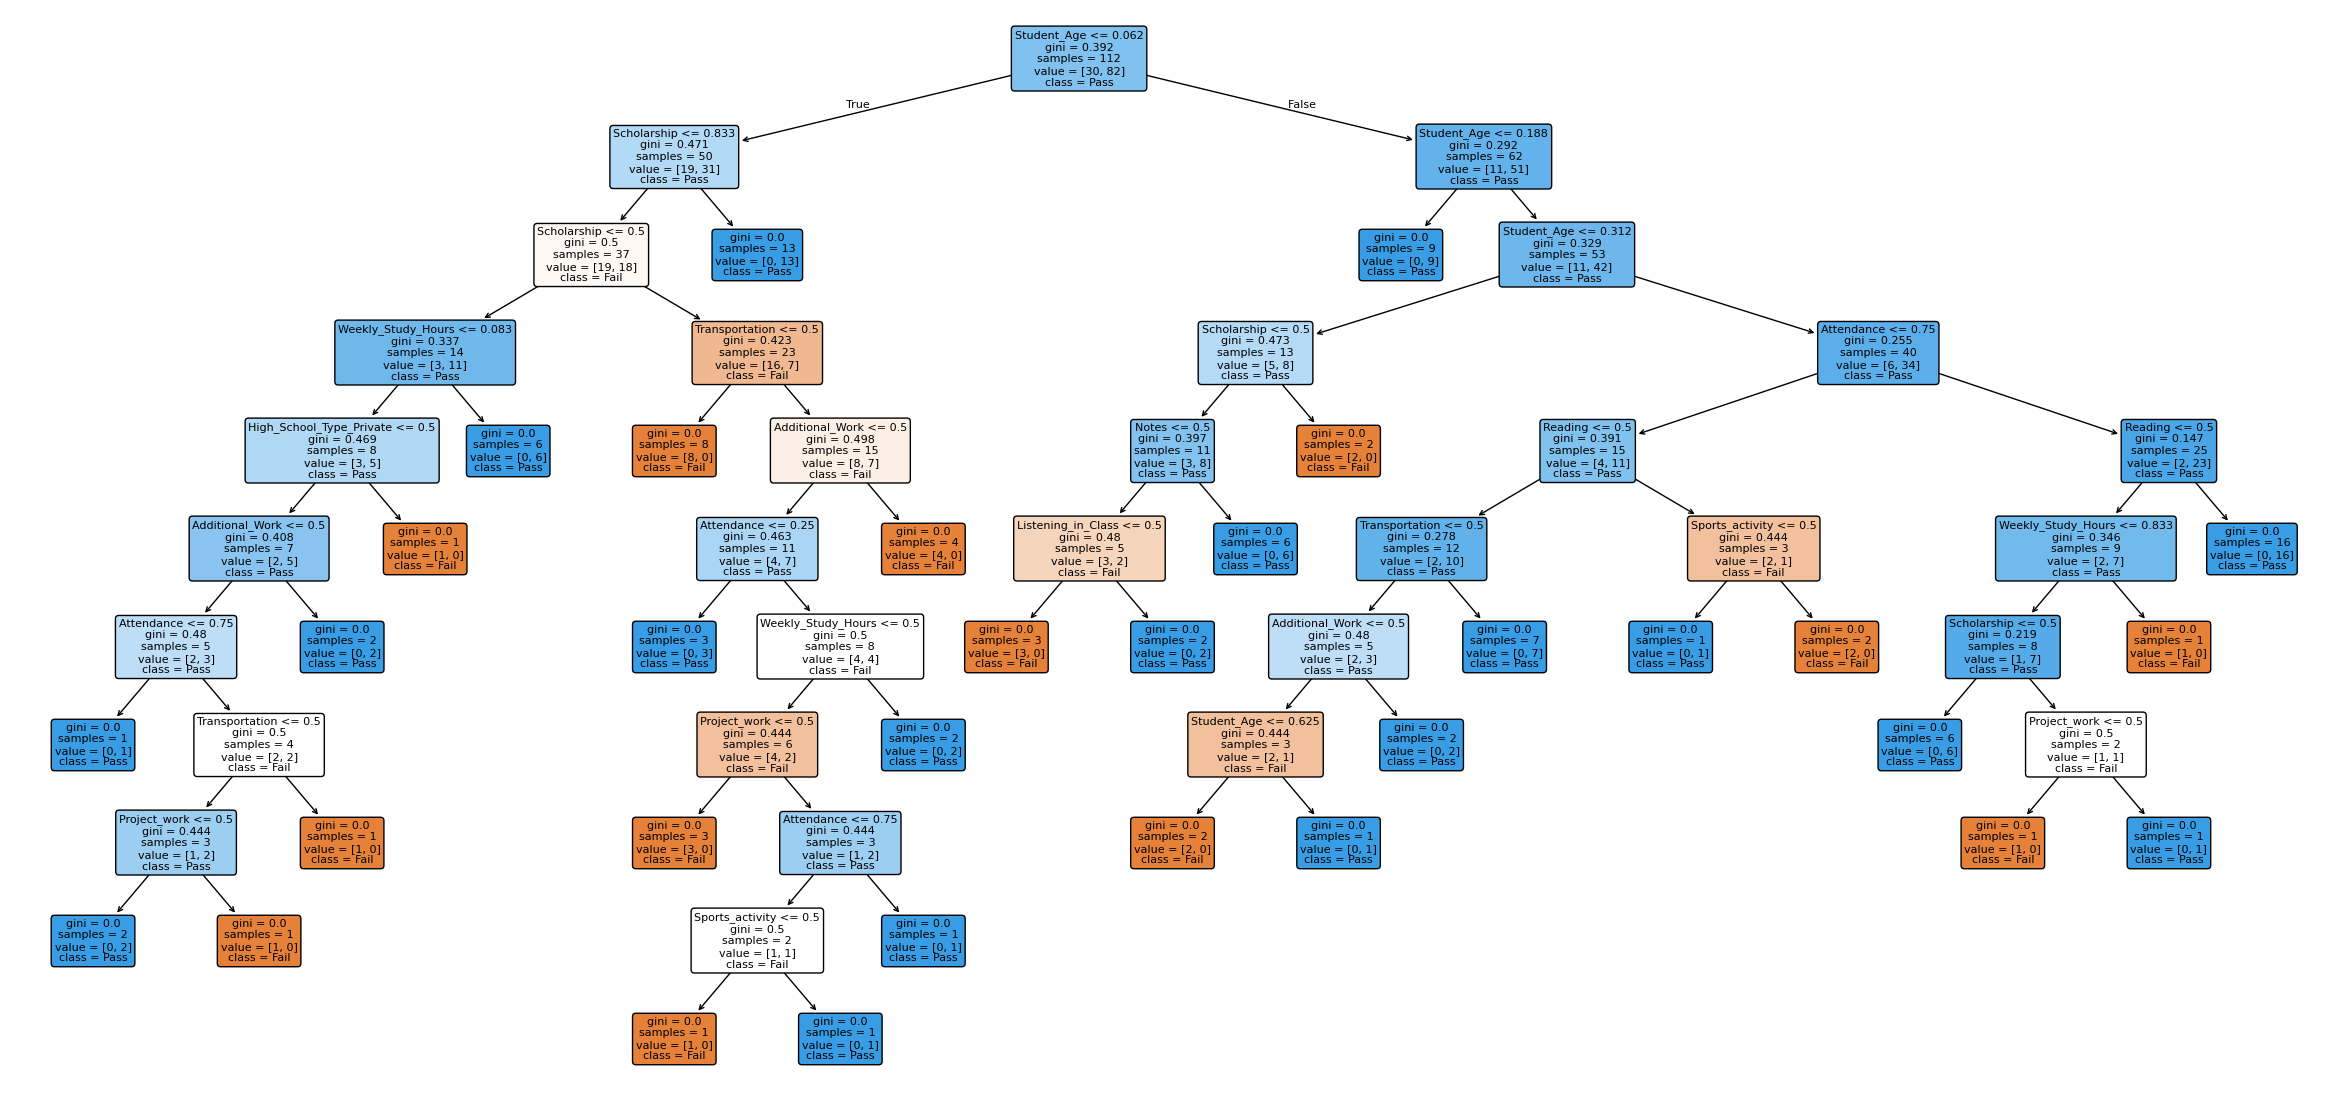

BEFORE tuning: depth = 10, leaves = 32


In [31]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(30, 14))
plot_tree(models[1], filled=True, feature_names=X_train.columns,
          class_names=['Fail', 'Pass'], rounded=True, fontsize=8)
plt.show()
print(f"BEFORE tuning: depth = {models[1].get_depth()}, leaves = {models[1].get_n_leaves()}")

In [25]:
# Hyperparameter tuning (same idea as notebooks 4.01 and 5.01)
import warnings
warnings.filterwarnings("ignore")
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

def random_search(algo, hyperparameters, scoring='f1_macro'):
    clf = RandomizedSearchCV(algo, hyperparameters, cv=5, random_state=2015,
                             scoring=scoring, n_iter=20, refit=True)
    clf.fit(X_train, Y_train)
    return clf.best_params_

grids = [
    # Logistic Regression
    {'solver': ['liblinear'], 'C': uniform(loc=0.1, scale=19.9), 'penalty': ['l1', 'l2']},
    # Decision Tree
    {'criterion': ['gini', 'entropy'], 'max_depth': randint(2, 7),
     'min_samples_split': randint(2, 7), 'max_features': ['sqrt', 'log2', None]},
    # Random Forest
    {'n_estimators': randint(50, 500), 'max_depth': randint(2, 7),
     'min_samples_split': randint(2, 7), 'max_features': ['sqrt', 'log2', None]},
    # GBDT
    {'n_estimators': randint(25, 250), 'learning_rate': uniform(loc=0.01, scale=0.49),
     'max_depth': randint(2, 7)},
    # XGBDT
    {'n_estimators': randint(25, 250), 'eta': uniform(loc=0.01, scale=0.49),
     'max_depth': randint(2, 7)},
]

best_params = [random_search(a, g) for a, g in zip(algos, grids)]
for name, bp in zip(names, best_params):
    print(name, bp)

Logistic Regression {'C': np.float64(10.319145892739579), 'penalty': 'l2', 'solver': 'liblinear'}
Decision Tree {'criterion': 'entropy', 'max_depth': 3, 'max_features': None, 'min_samples_split': 4}
Random Forest {'max_depth': 6, 'max_features': None, 'min_samples_split': 6, 'n_estimators': 386}
GBDT {'learning_rate': np.float64(0.11121882855934678), 'max_depth': 2, 'n_estimators': 137}
XGBDT {'eta': np.float64(0.15038334204940854), 'max_depth': 4, 'n_estimators': 178}


In [26]:
# Re-train with the best settings and score on the TEST data
classes = [LogR, DTC, RF, GBDT, XGB]
tuned_models = []
for cls, bp in zip(classes, best_params):
    extra = {} if cls is LogR else {'random_state': 1984}
    tuned_models.append(cls(**bp, **extra).fit(X_train, Y_train))

evaluate(tuned_models, X_train, Y_train, "TUNED - TRAINING data")
evaluate(tuned_models, X_test,  Y_test,  "TUNED - TEST data (the one that matters)")

===== TUNED - TRAINING data =====
Logistic Regression  accuracy=0.76  macro precision=0.72  macro recall=0.58  macro F1=0.58
Decision Tree        accuracy=0.81  macro precision=0.77  macro recall=0.72  macro F1=0.74
Random Forest        accuracy=0.89  macro precision=0.90  macro recall=0.82  macro F1=0.85
GBDT                 accuracy=0.92  macro precision=0.92  macro recall=0.87  macro F1=0.89
XGBDT                accuracy=0.99  macro precision=0.99  macro recall=0.98  macro F1=0.99

===== TUNED - TEST data (the one that matters) =====
Logistic Regression  accuracy=0.71  macro precision=0.62  macro recall=0.62  macro F1=0.62
Decision Tree        accuracy=0.79  macro precision=0.71  macro recall=0.67  macro F1=0.68
Random Forest        accuracy=0.71  macro precision=0.59  macro recall=0.57  macro F1=0.58
GBDT                 accuracy=0.71  macro precision=0.62  macro recall=0.62  macro F1=0.62
XGBDT                accuracy=0.61  macro precision=0.50  macro recall=0.50  macro F1=0.50



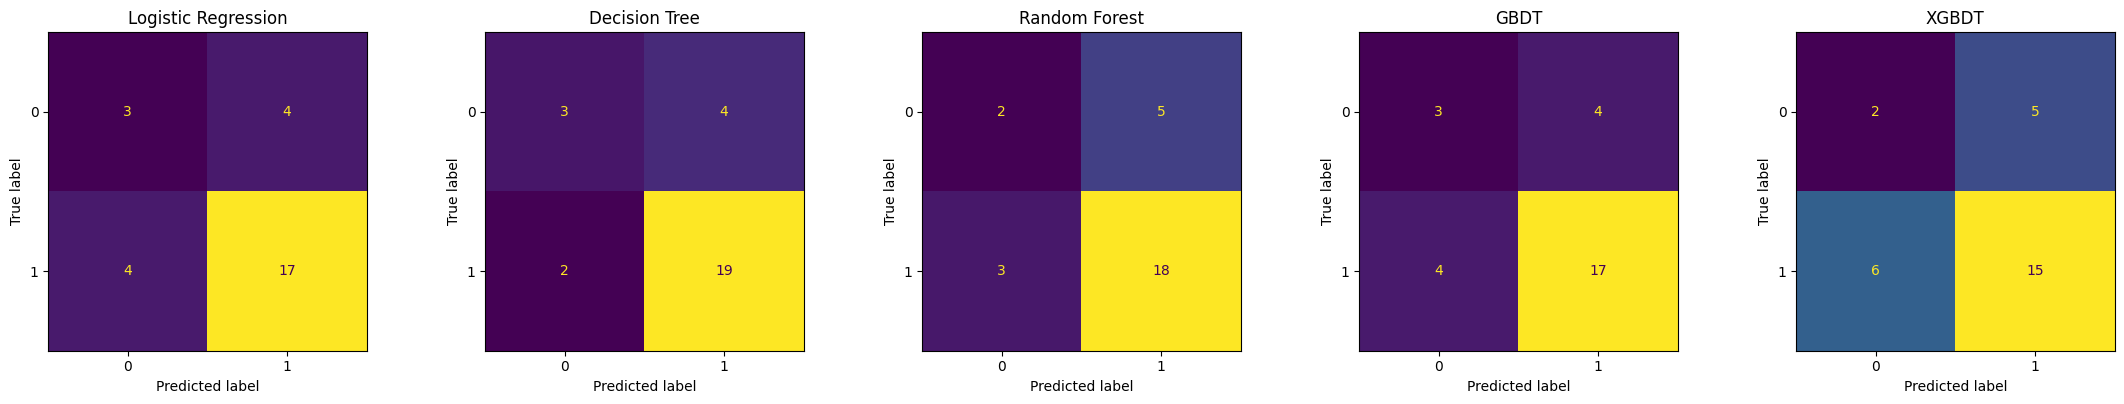

In [27]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay as CM

fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, name, model in zip(axes, names, tuned_models):
    CM.from_predictions(Y_test, model.predict(X_test), ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [28]:
# Which features matter? (use on the model you pick)
import pandas as pd

# Logistic regression: coefficient = push towards pass (+) or fail (-)
coefs = pd.Series(tuned_models[0].coef_[0], index=X_train.columns).sort_values(key=abs, ascending=False)
print("Logistic Regression coefficients:\n", coefs.round(2), "\n")

# Random forest: importance = how much the feature was used to split
imp = pd.Series(tuned_models[2].feature_importances_, index=X_train.columns).sort_values(ascending=False)
print("Random Forest importances:\n", imp.round(2))

Logistic Regression coefficients:
 Student_Age                 1.85
Reading                     0.87
Transportation              0.69
Attendance                 -0.67
High_School_Type_State     -0.57
Sports_activity            -0.53
Notes                       0.47
Listening_in_Class          0.39
High_School_Type_Private   -0.24
Scholarship                 0.14
Additional_Work            -0.09
Weekly_Study_Hours         -0.05
Project_work               -0.04
dtype: float64 

Random Forest importances:
 Scholarship                 0.26
Student_Age                 0.18
Attendance                  0.09
Weekly_Study_Hours          0.09
Transportation              0.07
Sports_activity             0.07
Project_work                0.05
Notes                       0.05
Reading                     0.04
Listening_in_Class          0.03
Additional_Work             0.03
High_School_Type_State      0.02
High_School_Type_Private    0.01
dtype: float64


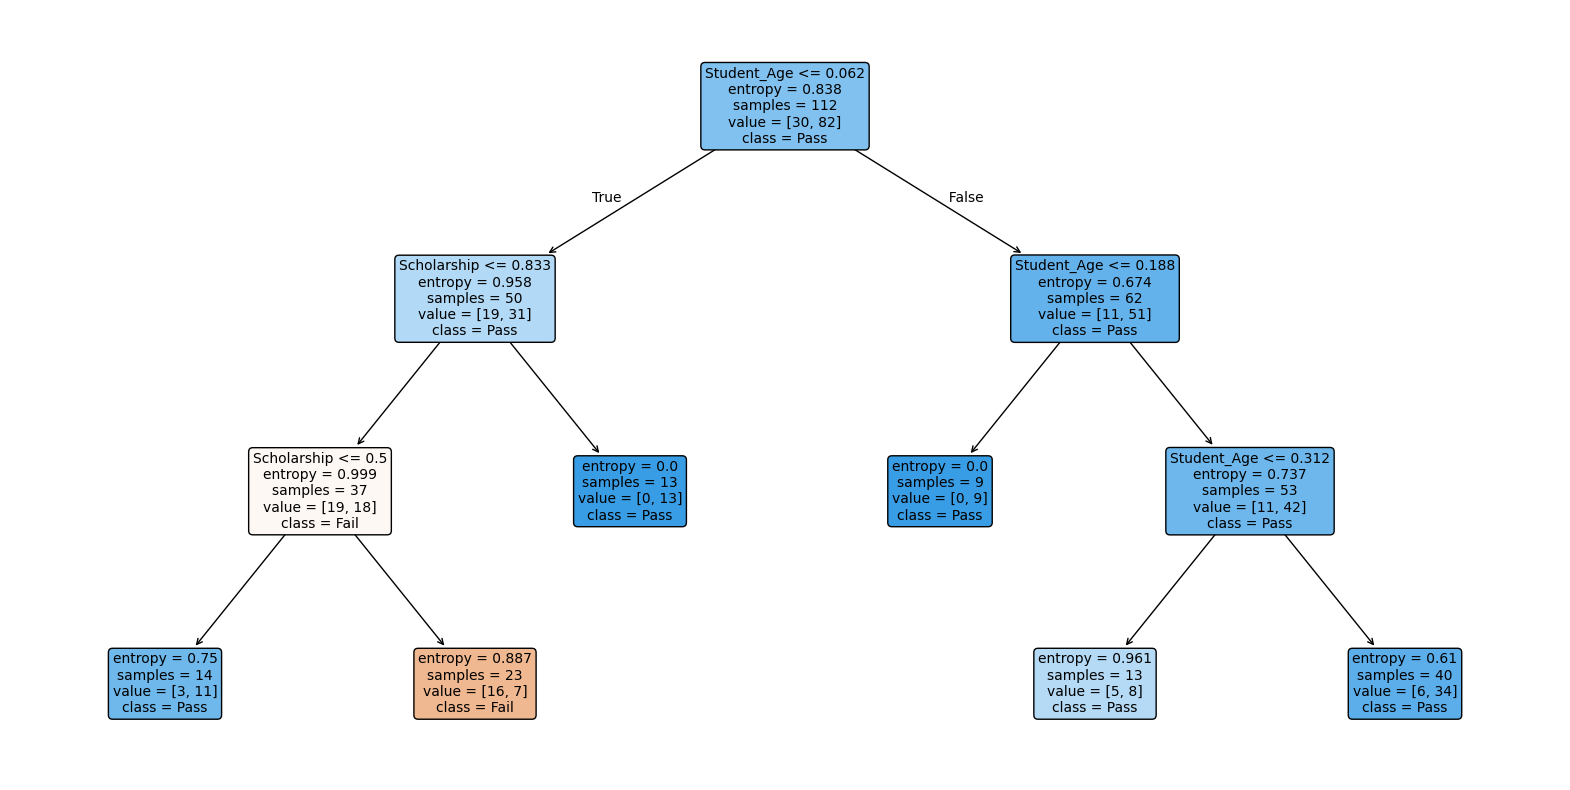

In [29]:
#i wanted to inlcude the trees aswell - but missed them on the first part so here they are
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(tuned_models[1], filled=True, feature_names=X_train.columns,
          class_names=['Fail', 'Pass'], rounded=True, fontsize=10)
plt.show()

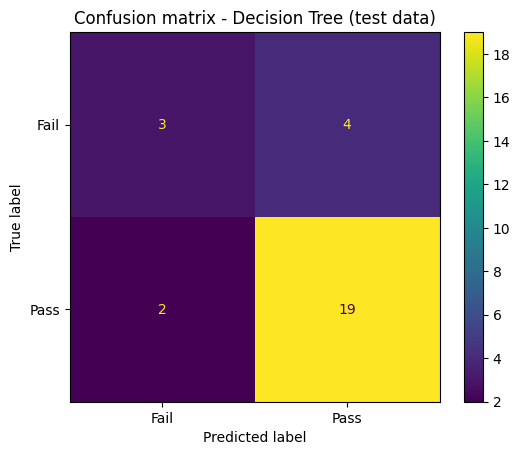

In [30]:
winner = 1   # 0=LogR, 1=Tree, 2=RF, 3=GBDT, 4=XGBDT
CM.from_predictions(Y_test, tuned_models[winner].predict(X_test),
                    display_labels=['Fail', 'Pass'])
plt.title(f"Confusion matrix - {names[winner]} (test data)")
plt.show()